# 第 00 章　PyTorch 入门：从一张照片认识张量

后面所有章节都在用 PyTorch 拆解 VLM，所以先把会反复用到的操作练熟。本章全部围绕**一张照片**进行，每一步都画出来。

| 小节 | 学什么 | 后面哪里会用到 |
|---|---|---|
| 1 | 张量的形状 / 类型 / 设备 | 处处 |
| 2 | 图片 → 张量 | 第 02 章预处理 |
| 3 | `reshape` / `permute`，把照片切成小块 | 第 03 章 patch、第 04 章 pixel shuffle |
| 4 | 广播与归一化 | 第 02 章 |
| 5 | 矩阵乘法与 `nn.Linear` | 第 03～05 章所有线性层 |
| 6 | MPS：Mac 的 GPU | 处处 |
| 7 | 自动求导与梯度下降 | 第 01 章训练 CNN |
| 8 | `nn.Module` 自定义网络 | 第 01、03、05 章手写网络 |
| 9 | forward hook 偷看中间层 | 第 01、03、05 章可视化 |

**使用方法**：选择内核「SmolVLM 学习 (.venv)」，从上到下按 `Shift+Enter` 逐格运行。

## 0. 准备工作
找到项目根目录，导入共享工具库 `vlmlab`（里面是画图和加载模型的小函数，源码在 `vlmlab/` 目录，可以随时打开看）。

In [1]:
import sys, pathlib  # sys 管理导入路径，pathlib 处理文件路径
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "vlmlab").exists())  # 从当前目录往上找，直到找到含 vlmlab 的项目根目录
sys.path.insert(0, str(ROOT))  # 把根目录加入导入路径，这样才能 import vlmlab

import time  # 计时
import torch  # PyTorch 主库
import torch.nn as nn  # 神经网络的"积木"：各种层
import torch.nn.functional as F  # 函数式接口：不带参数的运算（激活函数、卷积函数等）
import matplotlib.pyplot as plt  # 画图
from vlmlab import setup_matplotlib, seed_everything, get_device, load_photo, show_images, log_y, ActivationCache  # 共享工具

setup_matplotlib()  # 让图表能显示中文
seed_everything(0)  # 固定随机种子，保证结果可复现
device = get_device()  # Mac 上会得到 mps
print("PyTorch 版本:", torch.__version__)  # 打印版本
print("使用设备:", device)  # 打印设备

PyTorch 版本: 2.14.1
使用设备: mps


## 1. 张量（Tensor）是什么
张量就是**多维数组**，和 NumPy 的 `ndarray` 很像，但多两项能力：能放到 GPU 上算，能自动求导。

每个张量有三个最重要的属性：
- `shape`：形状，每一维有多长
- `dtype`：数据类型，比如 `float32`、`int64`
- `device`：放在哪，`cpu` 还是 `mps`

In [2]:
a = torch.tensor(3.14)  # 0 维张量：一个数（标量）
b = torch.tensor([1.0, 2.0, 3.0])  # 1 维张量：向量
c = torch.zeros(2, 3)  # 2 维张量：2 行 3 列的矩阵，全 0
d = torch.arange(24).reshape(2, 3, 4)  # 3 维张量：0~23 排成 2×3×4
for name, t in [("a", a), ("b", b), ("c", c), ("d", d)]:  # 逐个打印
    print(f"{name}: shape={tuple(t.shape)}, ndim={t.ndim}, dtype={t.dtype}, device={t.device}")  # 形状、维数、类型、设备
print(d)  # 看看 3 维张量长什么样：2 个 3×4 的矩阵

a: shape=(), ndim=0, dtype=torch.float32, device=cpu
b: shape=(3,), ndim=1, dtype=torch.float32, device=cpu
c: shape=(2, 3), ndim=2, dtype=torch.float32, device=cpu
d: shape=(2, 3, 4), ndim=3, dtype=torch.int64, device=cpu
tensor([[[ 0,  1,  2,  3],
         [ 4,  5,  6,  7],
         [ 8,  9, 10, 11]],

        [[12, 13, 14, 15],
         [16, 17, 18, 19],
         [20, 21, 22, 23]]])


**怎么读 shape**：`(2, 3, 4)` 从左往右读，"2 个、每个 3 行、每行 4 个数"。后面会看到很多这样的形状：
- 一张图：`[3, H, W]`，即 3 个颜色通道，每个通道是 H×W 的矩阵
- 一批图：`[B, 3, H, W]`，B 是批大小（batch）
- 一串 token：`[B, N, D]`，N 个 token，每个是 D 维向量

## 2. 图片 → 张量
照片在电脑里就是一个 `高 × 宽 × 3` 的数字阵列，每个数是 0～255 的亮度。PyTorch 习惯把**通道放在最前面**：`[3, H, W]`。

In [3]:
photo = load_photo()  # 读入照片（PIL 图片对象）
print("原始照片尺寸（宽, 高）:", photo.size)  # PIL 的 size 是 (宽, 高)，注意顺序和张量相反
small = photo.resize((256, 192))  # 缩小一点，方便演示
import numpy as np  # NumPy
arr = np.asarray(small)  # PIL → NumPy 数组，形状 [H, W, 3]，类型 uint8
x = torch.from_numpy(arr.copy())  # NumPy → 张量（copy 让张量拥有自己的内存）
print("NumPy 风格的形状 [H, W, C]:", tuple(x.shape), x.dtype)  # [192, 256, 3]，uint8
x = x.permute(2, 0, 1)  # 交换维度顺序：把第 2 维（通道）挪到最前 → [3, H, W]
x = x.float() / 255.0  # 转成浮点数并缩放到 0~1，神经网络都用浮点数计算
print("PyTorch 风格的形状 [C, H, W]:", tuple(x.shape), x.dtype)  # [3, 192, 256]，float32
print("左上角像素的 RGB 值:", x[:, 0, 0])  # 取所有通道、第 0 行、第 0 列

原始照片尺寸（宽, 高）: (5712, 4284)
NumPy 风格的形状 [H, W, C]: (192, 256, 3) torch.uint8
PyTorch 风格的形状 [C, H, W]: (3, 192, 256) torch.float32
左上角像素的 RGB 值: tensor([0.2196, 0.0863, 0.0157])


把 3 个通道拆开看：每个通道本身就是一张灰度图。红色通道里越亮的地方，原图越红。

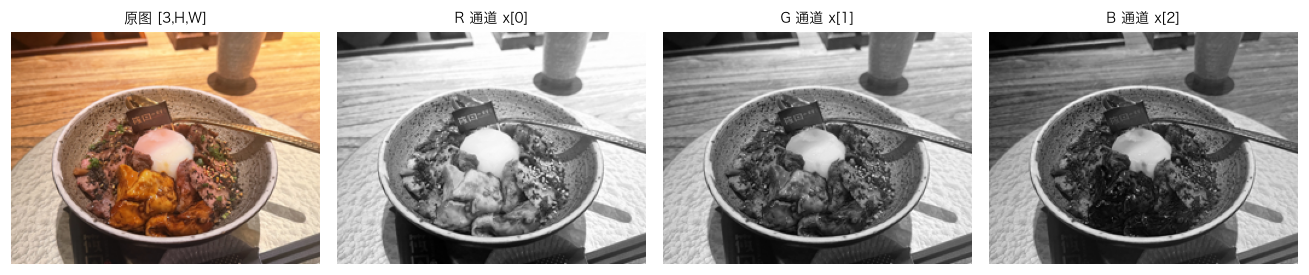

In [4]:
show_images(  # 并排显示四张图
    [x, x[0], x[1], x[2]],  # 原图 + R、G、B 三个通道（x[0] 就是第 0 个通道）
    titles=["原图 [3,H,W]", "R 通道 x[0]", "G 通道 x[1]", "B 通道 x[2]"],  # 标题
    cmap="gray",  # 单通道用灰度显示
    size=3,  # 每张图的大小
)

## 3. 形状变换：`reshape`、`permute`，把照片切成小块

这是**最重要**的一节。ViT 的第一步就是把图片切成 16×16 的小块（patch）。用张量操作完成切块，只需要一次 `reshape` 和一次 `permute`：

```
[3, H, W]
  → reshape →  [3, H/p, p, W/p, p]       把高、宽各拆成"第几块 × 块内第几个像素"
  → permute →  [H/p, W/p, 3, p, p]       把"第几块"挪到前面
  → reshape →  [块数, 3, p, p]
```

先用一个 4×4 的小矩阵热身，数字就是位置编号，方便追踪。

In [5]:
toy = torch.arange(16).reshape(4, 4)  # 4×4 的矩阵，数字 0~15
print("原矩阵:\n", toy)  # 打印
blocks = toy.reshape(2, 2, 2, 2)  # 拆成 [行块, 块内行, 列块, 块内列]
blocks = blocks.permute(0, 2, 1, 3)  # 调换成 [行块, 列块, 块内行, 块内列]
blocks = blocks.reshape(4, 2, 2)  # 合并前两维 → 4 个 2×2 小块
for i, blk in enumerate(blocks):  # 逐块打印
    print(f"第 {i} 块:\n{blk}")  # 左上块应该是 [[0,1],[4,5]]

原矩阵:
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11],
        [12, 13, 14, 15]])
第 0 块:
tensor([[0, 1],
        [4, 5]])
第 1 块:
tensor([[2, 3],
        [6, 7]])
第 2 块:
tensor([[ 8,  9],
        [12, 13]])
第 3 块:
tensor([[10, 11],
        [14, 15]])


同样的操作用在照片上。`p = 32`，192×256 的照片切成 6×8 = 48 块。

切块后的形状: (48, 3, 32, 32)


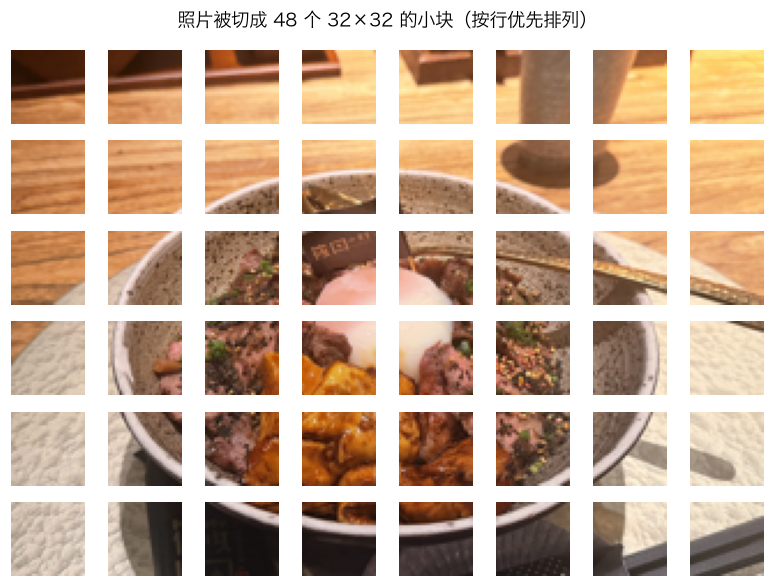

In [6]:
p = 32  # 每块边长 32 像素
C, H, W = x.shape  # 拆出通道数、高、宽
patches = x.reshape(C, H // p, p, W // p, p)  # [3, 6, 32, 8, 32]
patches = patches.permute(1, 3, 0, 2, 4)  # [6, 8, 3, 32, 32]：块的行号、块的列号放到最前
patches = patches.reshape(-1, C, p, p)  # [48, 3, 32, 32]；-1 表示"这一维自动算"
print("切块后的形状:", tuple(patches.shape))  # 48 个小块，每块 3×32×32
show_images(list(patches), cols=8, size=0.9, suptitle="照片被切成 48 个 32×32 的小块（按行优先排列）")  # 把 48 块排成 6 行 8 列显示

小块排回原位置，又拼出原图。这一步验证切块操作是可逆的，没有丢失任何信息。

In [7]:
back = patches.reshape(H // p, W // p, C, p, p)  # 先恢复成 [6, 8, 3, 32, 32]
back = back.permute(2, 0, 3, 1, 4).reshape(C, H, W)  # 维度换回 [3, 6, 32, 8, 32] 再合并成 [3, 192, 256]
print("拼回后与原图完全相同吗？", torch.equal(back, x))  # 应该是 True

拼回后与原图完全相同吗？ True


**记住**：`reshape` 只改变"怎么看"这串数字，不改变数字本身的排列；`permute` 改变维度的顺序。另外两个常用的：
- `unsqueeze(0)`：在最前面加一个长度为 1 的维度，常用来加 batch 维
- `flatten(start_dim)`：把从某维开始的所有维度压平

In [8]:
xb = x.unsqueeze(0)  # [3,H,W] → [1,3,H,W]：一批里只有一张图
print("加 batch 维:", tuple(xb.shape))  # 打印
print("压平空间维:", tuple(xb.flatten(2).shape))  # [1, 3, H*W]：每个通道的像素排成一行
print("转置最后两维:", tuple(xb.flatten(2).transpose(1, 2).shape))  # [1, H*W, 3]：每个像素是一个 3 维向量，ViT 里就是这样把图变成 token 序列的

加 batch 维: (1, 3, 192, 256)
压平空间维: (1, 3, 49152)
转置最后两维: (1, 49152, 3)


## 4. 广播（broadcasting）与归一化
神经网络喜欢均值约为 0 的输入。SmolVLM 的预处理是：`(像素 - 0.5) / 0.5`，把 0~1 变成 -1~1。

下面先用这张照片**自己的**每通道均值和标准差做归一化（每个通道各不相同），需要用**广播**：形状为 `[3, 1, 1]` 的张量和 `[3, H, W]` 运算时，会自动在 H、W 方向复制。

mean 的形状: (3, 1, 1)
归一化前 每通道均值: tensor([0.6642, 0.5106, 0.3867])
归一化后 每通道均值: tensor([-1.1424e-07, -1.7633e-07, -4.3151e-08]) 标准差: tensor([1.0000, 1.0000, 1.0000])


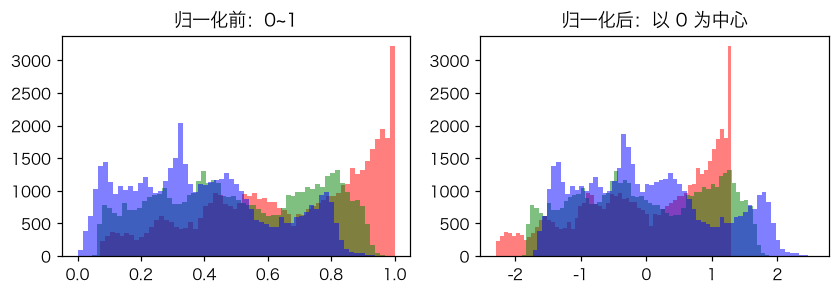

In [9]:
mean = x.mean(dim=(1, 2), keepdim=True)  # 每个通道在 H、W 上求均值；keepdim=True 保留维度，形状是 [3,1,1] 而不是 [3]
std = x.std(dim=(1, 2), keepdim=True)  # 每个通道的标准差，同样是 [3,1,1]
print("mean 的形状:", tuple(mean.shape))  # (3, 1, 1)
x_norm = (x - mean) / std  # 广播：[3,H,W] 和 [3,1,1] 逐元素运算
print("归一化前 每通道均值:", x.mean(dim=(1, 2)))  # 在 H、W 两个维度上求均值，剩下 3 个数
print("归一化后 每通道均值:", x_norm.mean(dim=(1, 2)), "标准差:", x_norm.std(dim=(1, 2)))  # 均值≈0，标准差≈1
fig, axes = plt.subplots(1, 2, figsize=(9, 2.6))  # 两个子图
for ch, color in enumerate("rgb"):  # 三个通道
    axes[0].hist(x[ch].flatten().numpy(), bins=60, color=color, alpha=0.5)  # 归一化前的分布
    axes[1].hist(x_norm[ch].flatten().numpy(), bins=60, color=color, alpha=0.5)  # 归一化后的分布
axes[0].set_title("归一化前：0~1")  # 标题
axes[1].set_title("归一化后：以 0 为中心")  # 标题
plt.show()  # 显示

## 5. 矩阵乘法与 `nn.Linear`
Transformer 里 90% 的计算是矩阵乘法。`nn.Linear(in, out)` 就是 `y = x @ W.T + b`。

下面把每个像素（3 维 RGB 向量）通过一个线性层变成 2 维。这就是 ViT 里"把 patch 变成向量"的缩小版。

权重形状: (2, 3) 偏置形状: (2,)
输出形状: (49152, 2)
两种算法一样吗？ True


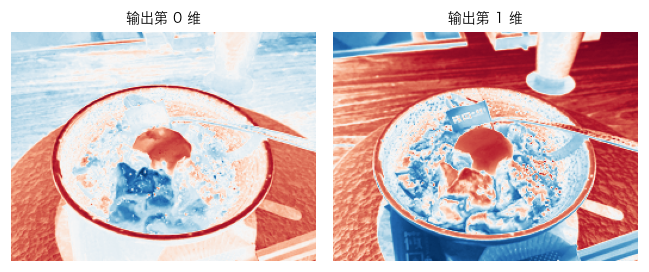

In [10]:
lin = nn.Linear(3, 2)  # 输入 3 维，输出 2 维；权重随机初始化
pixels = x.flatten(1).T  # [H*W, 3]：每行是一个像素的 RGB
y1 = lin(pixels)  # 用层来算
y2 = pixels @ lin.weight.T + lin.bias  # 手写矩阵乘法
print("权重形状:", tuple(lin.weight.shape), "偏置形状:", tuple(lin.bias.shape))  # [2,3] 和 [2]
print("输出形状:", tuple(y1.shape))  # [H*W, 2]
print("两种算法一样吗？", torch.allclose(y1, y2, atol=1e-6))  # True；浮点运算顺序不同会有 1e-7 级别的舍入差，所以用 allclose 而不是 equal
show_images([y1[:, 0].reshape(H, W), y1[:, 1].reshape(H, W)], titles=["输出第 0 维", "输出第 1 维"], cmap="RdBu", size=3)  # 输出的两维各自排回图片形状

## 6. MPS：用 Mac 的 GPU 计算
`.to(device)` 把张量或模型搬到 GPU。**参与同一次运算的张量必须在同一个设备上**，否则会报错。

GPU 是异步执行的，计时前要调用 `torch.mps.synchronize()` 等它真正算完。

In [11]:
def bench(dev, n=4096, reps=10):  # 测 n×n 矩阵乘法的平均耗时
    m = torch.randn(n, n, device=dev)  # 直接在目标设备上创建随机矩阵
    m @ m  # 先跑一次"热身"，让 GPU 完成初始化
    if dev.type == "mps":  # GPU 需要同步
        torch.mps.synchronize()  # 等待之前的计算完成
    t = time.time()  # 开始计时
    for _ in range(reps):  # 重复多次取平均
        m @ m  # 矩阵乘法
    if dev.type == "mps":  # GPU 需要同步
        torch.mps.synchronize()  # 等待全部完成
    return (time.time() - t) / reps  # 平均每次耗时（秒）

t_cpu = bench(torch.device("cpu"))  # CPU 耗时
t_gpu = bench(device)  # MPS 耗时
print(f"4096×4096 矩阵乘法：CPU {t_cpu*1000:.1f} ms，{device} {t_gpu*1000:.1f} ms，加速 {t_cpu/t_gpu:.1f} 倍")  # 对比

4096×4096 矩阵乘法：CPU 67.4 ms，mps 28.2 ms，加速 2.4 倍


## 7. 自动求导（autograd）与梯度下降
训练神经网络 = 不断调整参数让损失变小。PyTorch 会自动算出"每个参数往哪个方向调、调多少"，也就是梯度。

最小例子：$y = w^2$，在 $w=3$ 处的导数是 $2w = 6$。

In [12]:
w = torch.tensor(3.0, requires_grad=True)  # requires_grad=True：告诉 PyTorch 要追踪它的计算
y = w ** 2  # 前向计算
y.backward()  # 反向传播：自动求 dy/dw
print("dy/dw =", w.grad)  # 6.0

dy/dw = tensor(6.)


用同样的机制做一件有用的事：照片偏暖色，我们想学一个**颜色校正矩阵**（3×3 线性层），让照片接近黑白。目标图是灰度图。

这就是完整的训练循环：**前向 → 算损失 → 反向 → 更新参数 → 清空梯度**。第 01 章训练 CNN 也是这五步。

这里用 `nn.Conv2d(3, 3, kernel_size=1)`，即 **1×1 卷积**。它对每个像素做同一个 3→3 的线性变换，和对 `[H*W, 3]` 用 `nn.Linear(3, 3)` 在数学上完全等价（下面会验证）。

> ⚠️ **踩坑记录**：在本机（macOS 27 + PyTorch 2.14）上，`nn.Linear` 在 MPS 上做反向传播时，如果输入维度很小（3）而行数很多（≥4096），会卡死。1×1 卷积走另一条计算路径，不会卡。遇到 MPS 的怪问题时，可以换一种等价写法，或者先在 CPU 上跑，确认代码本身没有错。

1×1 卷积 与 nn.Linear 等价吗？ True


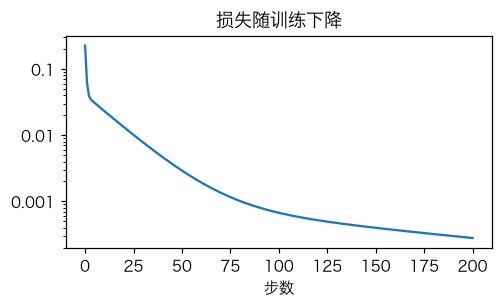

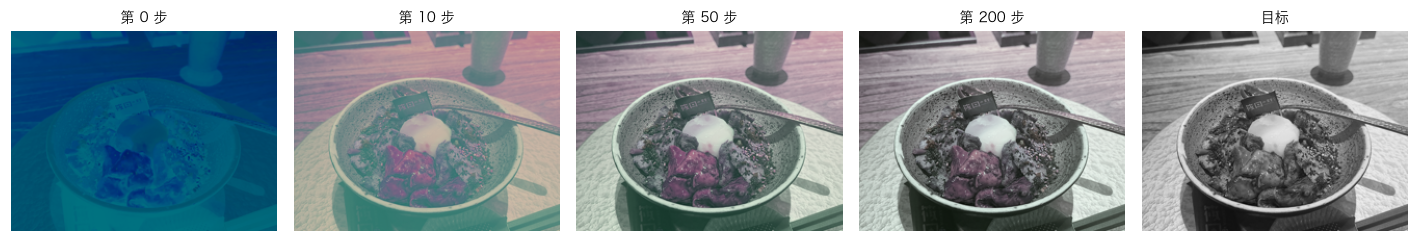

In [13]:
target = x.mean(0, keepdim=True).expand(3, H, W)  # 目标：三个通道都等于平均亮度（灰度图）
color = nn.Conv2d(3, 3, kernel_size=1).to(device)  # 待学习的颜色变换（1×1 卷积），放到 GPU
lin_equiv = nn.Linear(3, 3)  # 构造一个线性层，验证二者等价
lin_equiv.weight.data = color.weight.detach().cpu().view(3, 3)  # 卷积核 [3,3,1,1] 压成 [3,3] 就是线性层的权重
lin_equiv.bias.data = color.bias.detach().cpu()  # 偏置相同
same = torch.allclose(color.cpu()(x[None])[0].flatten(1).T, lin_equiv(x.flatten(1).T), atol=1e-6)  # 分别用卷积和线性层计算
color.to(device)  # 上一行把 color 临时搬到了 CPU，这里搬回 GPU
print("1×1 卷积 与 nn.Linear 等价吗？", same)  # True
opt = torch.optim.SGD(color.parameters(), lr=0.5)  # 优化器：随机梯度下降，学习率 0.5
inp = x[None].to(device)  # [1, 3, H, W] 输入图片
tgt = target[None].to(device)  # [1, 3, H, W] 目标图片
losses, snapshots = [], []  # 记录损失曲线和中间结果
for step in range(201):  # 训练 201 步
    out = color(inp)  # 1. 前向
    loss = F.mse_loss(out, tgt)  # 2. 损失：均方误差
    loss.backward()  # 3. 反向：算出所有参数的梯度
    opt.step()  # 4. 按梯度更新参数
    opt.zero_grad()  # 5. 清空梯度（PyTorch 默认会累加梯度）
    losses.append(loss.item())  # .item() 把单元素张量变成 Python 数字
    if step in (0, 10, 50, 200):  # 存几个中间结果
        snapshots.append(out.detach().cpu()[0].clamp(0, 1))  # detach 断开梯度，搬回 CPU，去掉 batch 维

plt.figure(figsize=(5, 2.5))  # 画损失曲线
plt.plot(losses)  # 曲线
log_y()  # 对数坐标更清楚（vlmlab 提供的小工具，见 viz.py）
plt.title("损失随训练下降")  # 标题
plt.xlabel("步数")  # 横轴
plt.show()  # 显示
show_images(snapshots + [target], titles=["第 0 步", "第 10 步", "第 50 步", "第 200 步", "目标"], size=2.6)  # 看照片怎么一步步变成黑白

## 8. 用 `nn.Module` 搭网络
自定义网络就是写一个继承 `nn.Module` 的类：
- `__init__` 里声明有哪些层（带参数的积木）
- `forward` 里写数据怎么流过这些层

下面搭一个迷你 CNN，第 01 章会正式训练它。

In [14]:
class TinyCNN(nn.Module):  # 继承 nn.Module
    def __init__(self, num_classes=3):  # 构造函数
        super().__init__()  # 必须先调用父类构造函数
        self.conv1 = nn.Conv2d(3, 8, kernel_size=3, padding=1)  # 卷积层：3 通道 → 8 通道，3×3 卷积核
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)  # 8 → 16 通道
        self.pool = nn.MaxPool2d(2)  # 2×2 最大池化，长宽各减半
        self.head = nn.Linear(16, num_classes)  # 分类头

    def forward(self, x):  # 前向计算
        x = self.pool(F.relu(self.conv1(x)))  # 卷积 → ReLU 激活 → 池化
        x = self.pool(F.relu(self.conv2(x)))  # 再来一次
        x = x.mean(dim=(2, 3))  # 全局平均池化：每个通道取平均，[B,16,h,w] → [B,16]
        return self.head(x)  # 输出每类的分数

net = TinyCNN().to(device)  # 实例化并搬到 GPU
print(net)  # 打印网络结构
for name, prm in net.named_parameters():  # 列出所有参数
    print(f"{name:15s} {tuple(prm.shape)}")  # 名字和形状
print("参数总数:", sum(p.numel() for p in net.parameters()))  # numel = 元素个数

TinyCNN(
  (conv1): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (head): Linear(in_features=16, out_features=3, bias=True)
)
conv1.weight    (8, 3, 3, 3)
conv1.bias      (8,)
conv2.weight    (16, 8, 3, 3)
conv2.bias      (16,)
head.weight     (3, 16)
head.bias       (3,)
参数总数: 1443


## 9. forward hook：偷看中间层
想看图片流过 `conv1` 之后变成什么，可以在这一层挂一个**钩子**：每次这层算完，PyTorch 都会调用钩子函数并把输出交给它。

先手写一次原生用法，再用 `vlmlab.ActivationCache` 简化，它就是把下面几行包装了一下。后面各章都用它看模型内部。

conv1 输出形状: (1, 8, 192, 256)
{'conv1': (1, 8, 192, 256), 'conv2': (1, 16, 96, 128)}


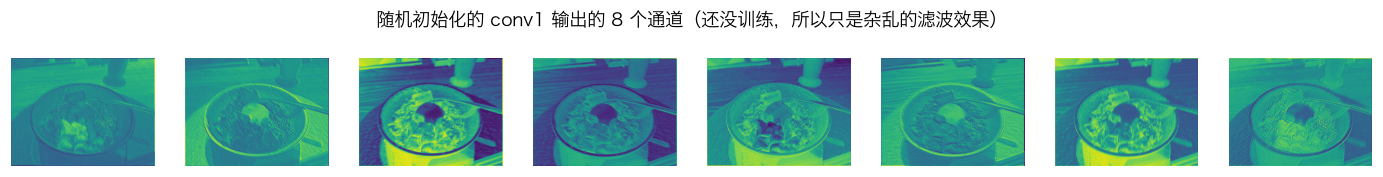

In [15]:
saved = {}  # 用来存中间结果
handle = net.conv1.register_forward_hook(lambda mod, inp, out: saved.update(conv1=out.detach().cpu()))  # 注册钩子：把输出存进字典
with torch.no_grad():  # 推理时不需要梯度，省内存
    net(xb.to(device))  # 跑一次前向
handle.remove()  # 用完删掉钩子
print("conv1 输出形状:", tuple(saved["conv1"].shape))  # [1, 8, H, W]

with ActivationCache(net, ["conv1", "conv2"]) as cache:  # 同时观察两层
    with torch.no_grad():  # 不需要梯度
        net(xb.to(device))  # 前向
print({k: tuple(v.shape) for k, v in cache.items()})  # conv2 的输入经过了一次池化，所以尺寸减半
show_images(list(cache["conv1"][0]), cols=8, cmap="viridis", size=1.6, suptitle="随机初始化的 conv1 输出的 8 个通道（还没训练，所以只是杂乱的滤波效果）")  # 8 张特征图

## 小结：速查表

| 操作 | 作用 | 例子 |
|---|---|---|
| `t.shape` / `t.dtype` / `t.device` | 查看属性 | `x.shape → [3,192,256]` |
| `reshape` / `view` | 改变看待方式 | `[3,H,W] → [3,H*W]` |
| `permute` / `transpose` | 交换维度 | `[H,W,3] → [3,H,W]` |
| `unsqueeze(0)` / `squeeze(0)` | 加 / 去掉长度为 1 的维度 | 加 batch 维 |
| `flatten(start)` | 压平 | `[B,C,H,W] → [B,C,H*W]` |
| 广播 | 形状不同也能运算 | `[3,H,W] - [3,1,1]` |
| `@` / `nn.Linear` | 矩阵乘法 / 线性层 | `y = x @ W.T + b` |
| `.to(device)` | 搬到 GPU | `x.to("mps")` |
| `requires_grad` / `backward()` | 自动求导 | 训练循环五步 |
| `nn.Module` | 自定义网络 | `__init__` + `forward` |
| `register_forward_hook` | 取出中间层输出 | 可视化 |
| `torch.no_grad()` | 推理时关闭梯度 | 省内存、更快 |

下一章：**卷积神经网络（CNN）是怎么"看"图片的**。